# Practical 1 — Uber Ride Price Prediction

**Subject:** Machine Learning (410242)  
**Class:** B.E. Computer Engineering, Semester I  
**Lab:** Laboratory Practice III (410246)

---

## 1. Aim

Predict the price of an Uber ride from a given pickup point to the agreed
drop-off location. Perform preprocessing, outlier detection, correlation
analysis, and compare **Linear Regression** with **Random Forest Regression**
using $R^2$, MAE and RMSE.

## 2. Dataset

**Uber Fares Dataset** — Kaggle:  
<https://www.kaggle.com/datasets/yasserh/uber-fares-dataset>

The dataset contains 200,000 trips with these columns:

| Column | Meaning |
|---|---|
| `fare_amount` | Fare in USD (target) |
| `pickup_datetime` | Date and time of pickup |
| `pickup_longitude`, `pickup_latitude` | Pickup coordinates |
| `dropoff_longitude`, `dropoff_latitude` | Drop-off coordinates |
| `passenger_count` | Number of passengers |
| `key`, `Unnamed: 0` | Identifiers (dropped) |

The CSV is stored as `data/uber.csv.gz` (the same data, gzipped to keep the
repository small).

## 3. Objectives

- Clean and preprocess a real-world regression dataset.
- Detect and treat outliers using the IQR rule and box plots.
- Engineer useful features (time parts and Haversine distance).
- Train Linear Regression and Random Forest models.
- Compare models with $R^2$, MAE and RMSE and interpret the results.

## 4. Theory

### 4.1 Linear Regression

Linear Regression models the target as a linear combination of features:

$$\hat{y} = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_p x_p.$$

The coefficients are chosen to minimise the residual sum of squares:

$$\text{RSS} = \sum_{i=1}^{n}(y_i-\hat{y}_i)^2.$$

It is simple and interpretable, but it cannot capture non-linear relationships
such as the interaction between distance and location.

### 4.2 Random Forest Regression

A Random Forest builds many decision trees on bootstrap samples and random
subsets of features. For regression, the prediction is the average of the
trees:

$$\hat{y} = \frac{1}{B}\sum_{b=1}^{B} T_b(x).$$

Averaging reduces variance, and random feature selection decorrelates the
trees. Random Forests capture non-linearities and interactions, at the cost of
interpretability and training time.

### 4.3 Evaluation metrics

$$R^2 = 1-\frac{\sum(y_i-\hat{y}_i)^2}{\sum(y_i-\bar{y})^2},\qquad
\text{MAE}=\frac{1}{n}\sum|y_i-\hat{y}_i|,\qquad
\text{RMSE}=\sqrt{\frac{1}{n}\sum(y_i-\hat{y}_i)^2}.$$

- $R^2$ close to 1 means the model explains most of the variance.
- MAE is in dollars and is easy to interpret.
- RMSE penalises large errors more heavily than MAE.

### 4.4 Haversine distance

Latitude/longitude are angles on a sphere, so Euclidean distance is not
appropriate. The Haversine formula gives the great-circle distance:

$$d=2R\arcsin\sqrt{\sin^2\frac{\Delta\phi}{2}+
\cos\phi_1\cos\phi_2\sin^2\frac{\Delta\lambda}{2}},$$

where $R\approx6371$ km. Distance is usually the strongest predictor of fare.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
plt.style.use("seaborn-v0_8-whitegrid")
sns.set_palette("husl")

DATA_DIR = Path("data")
if not DATA_DIR.exists():
    DATA_DIR = Path("ML/data")

print("Data directory:", DATA_DIR.resolve())

Data directory: /home/aathi/Desktop/SEM 7/PRACTICALS/LP3/ML/data


In [2]:
df = pd.read_csv(DATA_DIR / "uber.csv.gz")
print("Shape:", df.shape)
df.head()

Shape: (200000, 9)


,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  str    
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  str    
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), str(2)
memory usage: 13.7 MB


In [4]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,200000.0,NaN,NaN,NaN,27712503.68235,16013822.212829,1.0,13825346.25,27745495.0,41555300.75,55423567.0
key,200000,200000,2015-05-07 19:52:06.0000003,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fare_amount,200000.0,NaN,NaN,NaN,11.359955,9.901776,-52.0,6.0,8.5,12.5,499.0
pickup_datetime,200000,196629,2009-02-12 12:46:00 UTC,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
pickup_longitude,200000.0,NaN,NaN,NaN,-72.527638,11.437787,-1340.64841,-73.992065,-73.981823,-73.967154,57.418457
pickup_latitude,200000.0,NaN,NaN,NaN,39.935885,7.720539,-74.015515,40.734796,40.752592,40.767158,1644.421482
dropoff_longitude,199999.0,NaN,NaN,NaN,-72.525292,13.117408,-3356.6663,-73.991407,-73.980093,-73.963658,1153.572603
dropoff_latitude,199999.0,NaN,NaN,NaN,39.92389,6.794829,-881.985513,40.733823,40.753042,40.768001,872.697628
passenger_count,200000.0,NaN,NaN,NaN,1.684535,1.385997,0.0,1.0,1.0,2.0,208.0


### 4.1 Pre-processing

Steps:

1. Drop identifier columns (`Unnamed: 0`, `key`).
2. Parse `pickup_datetime` and extract hour, day, month, year and weekday.
3. Handle the two missing drop-off coordinates.
4. Remove physically impossible fares/coordinates.
5. Compute the Haversine distance.
6. Detect outliers with the IQR rule.

In [5]:
df = df.drop(columns=["Unnamed: 0", "key"])
df["pickup_datetime"] = pd.to_datetime(
    df["pickup_datetime"], errors="coerce", utc=True
)

print("Missing values before cleaning:")
print(df.isna().sum())
print("\nRows with an invalid datetime:", df["pickup_datetime"].isna().sum())

Missing values before cleaning:
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64

Rows with an invalid datetime: 0


In [6]:
# The two missing drop-off coordinates are only one row; drop it.
df = df.dropna(subset=["dropoff_latitude", "dropoff_longitude"]).copy()
df = df.dropna(subset=["pickup_datetime"])

# Time features.
df["hour"] = df["pickup_datetime"].dt.hour
df["day"] = df["pickup_datetime"].dt.day
df["month"] = df["pickup_datetime"].dt.month
df["year"] = df["pickup_datetime"].dt.year
df["dayofweek"] = df["pickup_datetime"].dt.dayofweek
df["is_weekend"] = (df["dayofweek"] >= 5).astype(int)

print("Shape after dropping missing rows:", df.shape)
df[["pickup_datetime", "hour", "day", "month", "year", "dayofweek"]].head()

Shape after dropping missing rows: (199999, 13)


,pickup_datetime,hour,day,month,year,dayofweek
0,2015-05-07 19:52:06+00:00,19,7,5,2015,3
1,2009-07-17 20:04:56+00:00,20,17,7,2009,4
2,2009-08-24 21:45:00+00:00,21,24,8,2009,0
3,2009-06-26 08:22:21+00:00,8,26,6,2009,4
4,2014-08-28 17:47:00+00:00,17,28,8,2014,3


In [7]:
def haversine_km(lat1, lon1, lat2, lon2):
    """Vectorised Haversine distance in kilometres."""
    radius = 6371.0088
    phi1 = np.radians(lat1)
    phi2 = np.radians(lat2)
    delta_phi = np.radians(lat2 - lat1)
    delta_lambda = np.radians(lon2 - lon1)

    a = (
        np.sin(delta_phi / 2.0) ** 2
        + np.cos(phi1) * np.cos(phi2) * np.sin(delta_lambda / 2.0) ** 2
    )
    return 2 * radius * np.arcsin(np.sqrt(a))


df["distance_km"] = haversine_km(
    df["pickup_latitude"],
    df["pickup_longitude"],
    df["dropoff_latitude"],
    df["dropoff_longitude"],
)
df[["distance_km", "fare_amount"]].describe()

,distance_km,fare_amount
count,199999.000000,199999.000000
mean,20.855379,11.359892
std,382.965171,9.901760
min,0.000000,-52.000000
25%,1.215224,6.000000
50%,2.120995,8.500000
75%,3.875175,12.500000
max,16409.261801,499.000000


In [8]:
# Remove physically invalid records.
before = len(df)
df = df[
    df["fare_amount"].between(0.01, 300)
    & df["passenger_count"].between(0, 6)
    & df["pickup_latitude"].between(-90, 90)
    & df["pickup_longitude"].between(-180, 180)
    & df["dropoff_latitude"].between(-90, 90)
    & df["dropoff_longitude"].between(-180, 180)
    & df["distance_km"].between(0.1, 130)
].copy()
after = len(df)
print(f"Removed {before - after:,} invalid rows; remaining: {after:,}")

Removed 7,268 invalid rows; remaining: 192,731


### 4.2 Outlier detection

The IQR rule flags a value as an outlier if it lies outside

$$[Q_1-1.5\,\text{IQR},\ Q_3+1.5\,\text{IQR}],\qquad \text{IQR}=Q_3-Q_1.$$

Box plots show the distribution before and after treatment. Fares have a long
right tail (airport trips, surcharges), so we report the outliers and keep only
the extreme 1% for modelling rather than deleting every statistically flagged
point.

In [9]:
def iqr_bounds(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr


for column in ["fare_amount", "distance_km", "passenger_count"]:
    lower, upper = iqr_bounds(df[column])
    outlier_count = ((df[column] < lower) | (df[column] > upper)).sum()
    print(
        f"{column:15s}: Q1-1.5IQR = {lower:8.2f}, "
        f"Q3+1.5IQR = {upper:8.2f}, outliers = {outlier_count:,}"
    )

fare_amount    : Q1-1.5IQR =    -3.75, Q3+1.5IQR =    22.25, outliers = 16,343
distance_km    : Q1-1.5IQR =    -2.70, Q3+1.5IQR =     7.95, outliers = 16,024
passenger_count: Q1-1.5IQR =    -0.50, Q3+1.5IQR =     3.50, outliers = 21,757


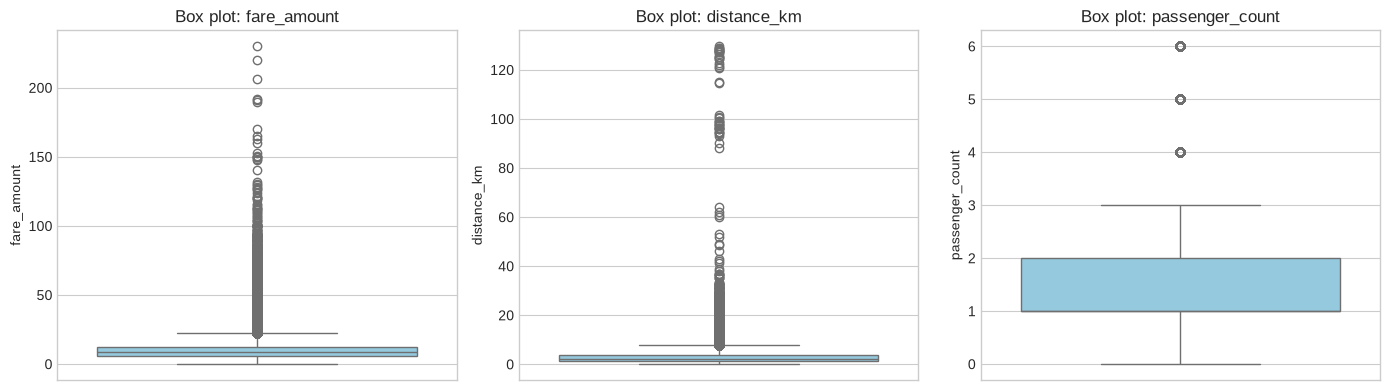

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for axis, column in zip(axes, ["fare_amount", "distance_km", "passenger_count"]):
    sns.boxplot(y=df[column], ax=axis, color="skyblue")
    axis.set_title(f"Box plot: {column}")
    axis.set_ylabel(column)
plt.tight_layout()
plt.show()

In [11]:
# Keep fares up to the 99th percentile and distances up to 100 km. This removes
# a small number of extreme values without discarding ordinary long trips.
fare_cap = df["fare_amount"].quantile(0.99)
distance_cap = 100.0
before = len(df)
df = df[(df["fare_amount"] <= fare_cap) & (df["distance_km"] <= distance_cap)].copy()
print(f"Fare cap (99th percentile): ${fare_cap:.2f}")
print(f"Removed {before - len(df):,} extreme rows; remaining: {len(df):,}")

Fare cap (99th percentile): $52.00
Removed 1,887 extreme rows; remaining: 190,844


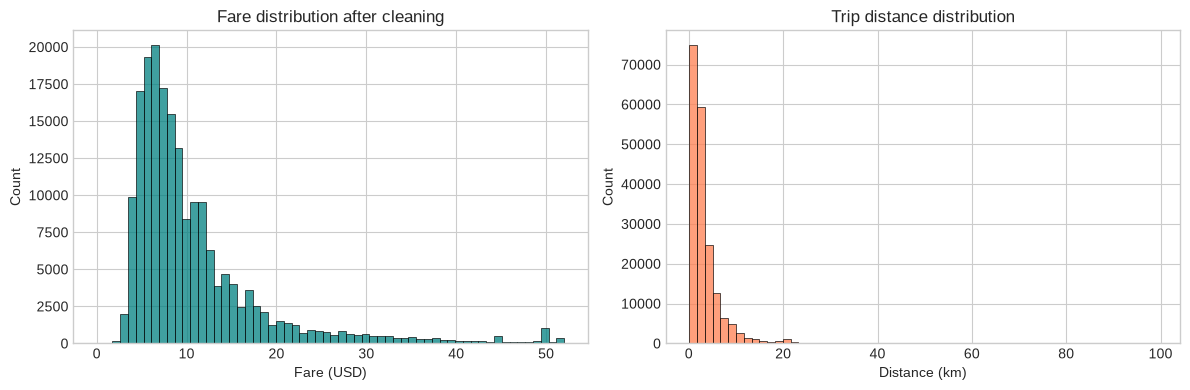

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["fare_amount"], bins=60, ax=axes[0], color="teal")
axes[0].set_title("Fare distribution after cleaning")
axes[0].set_xlabel("Fare (USD)")

sns.histplot(df["distance_km"], bins=60, ax=axes[1], color="coral")
axes[1].set_title("Trip distance distribution")
axes[1].set_xlabel("Distance (km)")
plt.tight_layout()
plt.show()

### 4.3 Correlation analysis

Correlation measures the linear association between two numeric variables:

$$r_{xy}=\frac{\sum(x_i-\bar{x})(y_i-\bar{y})}
{\sqrt{\sum(x_i-\bar{x})^2\sum(y_i-\bar{y})^2}}.$$

Values near $+1$ or $-1$ indicate a strong positive or negative linear
relationship; values near 0 indicate little linear relationship. Correlation
does **not** imply causation.

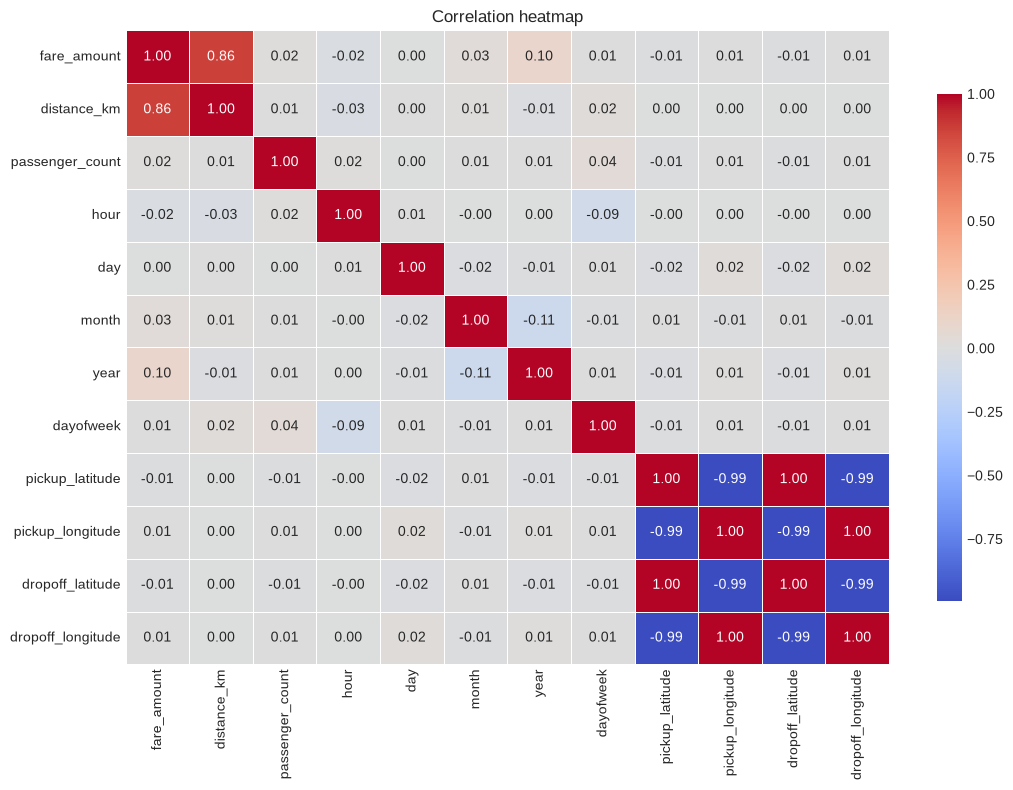

In [13]:
numeric_columns = [
    "fare_amount",
    "distance_km",
    "passenger_count",
    "hour",
    "day",
    "month",
    "year",
    "dayofweek",
    "pickup_latitude",
    "pickup_longitude",
    "dropoff_latitude",
    "dropoff_longitude",
]
correlation = df[numeric_columns].corr()

plt.figure(figsize=(11, 8))
sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8},
)
plt.title("Correlation heatmap")
plt.tight_layout()
plt.show()

In [14]:
print("Correlation with fare_amount (sorted):")
correlation["fare_amount"].sort_values(ascending=False)

Correlation with fare_amount (sorted):


fare_amount          1.000000
distance_km          0.860959
year                 0.101024
month                0.027845
passenger_count      0.015857
pickup_longitude     0.010684
dropoff_longitude    0.010534
dayofweek            0.006436
day                  0.001281
pickup_latitude     -0.007577
dropoff_latitude    -0.007679
hour                -0.020701
Name: fare_amount, dtype: float64

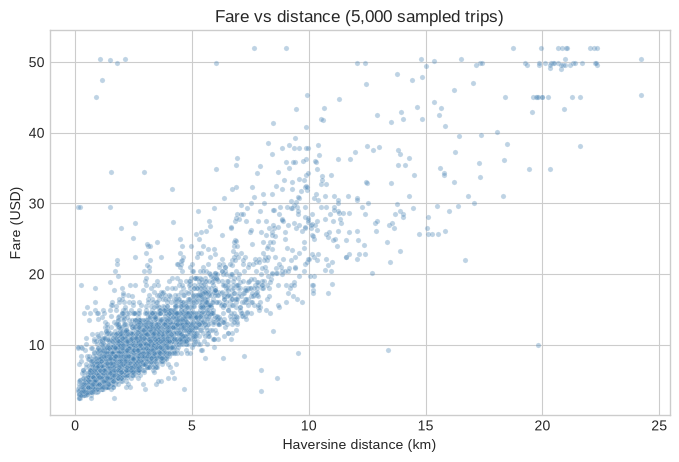

In [15]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df.sample(5_000, random_state=42),
    x="distance_km",
    y="fare_amount",
    alpha=0.35,
    s=14,
    color="steelblue",
)
plt.title("Fare vs distance (5,000 sampled trips)")
plt.xlabel("Haversine distance (km)")
plt.ylabel("Fare (USD)")
plt.show()

### 4.4 Feature selection and train/test split

We use the coordinates (pickup/drop-off), passenger count, time features and
the engineered distance. The target is `fare_amount`.

An 80/20 split is used. `random_state=42` makes the result reproducible.

In [16]:
feature_columns = [
    "pickup_longitude",
    "pickup_latitude",
    "dropoff_longitude",
    "dropoff_latitude",
    "passenger_count",
    "hour",
    "day",
    "month",
    "year",
    "dayofweek",
    "is_weekend",
    "distance_km",
]
target_column = "fare_amount"

X = df[feature_columns]
y = df[target_column]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Training rows:", len(X_train))
print("Test rows    :", len(X_test))
print("Features     :", len(feature_columns))

Training rows: 152675
Test rows    : 38169
Features     : 12


### 4.5 Linear Regression

In [17]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
linear_predictions = linear_model.predict(X_test)

linear_r2 = r2_score(y_test, linear_predictions)
linear_mae = mean_absolute_error(y_test, linear_predictions)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_predictions))

print("Linear Regression")
print(f"  R²   : {linear_r2:.4f}")
print(f"  MAE  : ${linear_mae:.4f}")
print(f"  RMSE : ${linear_rmse:.4f}")
print("\nIntercept:", round(linear_model.intercept_, 4))
print("\nCoefficients:")
for name, coefficient in zip(feature_columns, linear_model.coef_):
    print(f"  {name:20s} {coefficient: .6f}")

Linear Regression
  R²   : 0.7708
  MAE  : $2.0984
  RMSE : $3.7802

Intercept: -995.8904

Coefficients:
  pickup_longitude      2.163898
  pickup_latitude       8.397057
  dropoff_longitude    -2.041534
  dropoff_latitude     -8.292759
  passenger_count       0.064520
  hour                  0.006188
  day                   0.000561
  month                 0.071563
  year                  0.499205
  dayofweek             0.073317
  is_weekend           -0.628665
  distance_km           2.029156


### 4.6 Random Forest Regression

In [18]:
random_forest = RandomForestRegressor(
    n_estimators=100,
    max_depth=25,
    min_samples_leaf=5,
    n_jobs=-1,
    random_state=42,
)
random_forest.fit(X_train, y_train)
forest_predictions = random_forest.predict(X_test)

forest_r2 = r2_score(y_test, forest_predictions)
forest_mae = mean_absolute_error(y_test, forest_predictions)
forest_rmse = np.sqrt(mean_squared_error(y_test, forest_predictions))

print("Random Forest Regression")
print(f"  R²   : {forest_r2:.4f}")
print(f"  MAE  : ${forest_mae:.4f}")
print(f"  RMSE : ${forest_rmse:.4f}")

Random Forest Regression
  R²   : 0.8743
  MAE  : $1.5889
  RMSE : $2.7987


In [19]:
# Side-by-side comparison.
comparison = pd.DataFrame(
    {
        "model": ["Linear Regression", "Random Forest"],
        "R²": [linear_r2, forest_r2],
        "MAE (USD)": [linear_mae, forest_mae],
        "RMSE (USD)": [linear_rmse, forest_rmse],
    }
)
comparison

,model,R²,MAE (USD),RMSE (USD)
0,Linear Regression,0.770765,2.098395,3.780161
1,Random Forest,0.874347,1.588867,2.798704


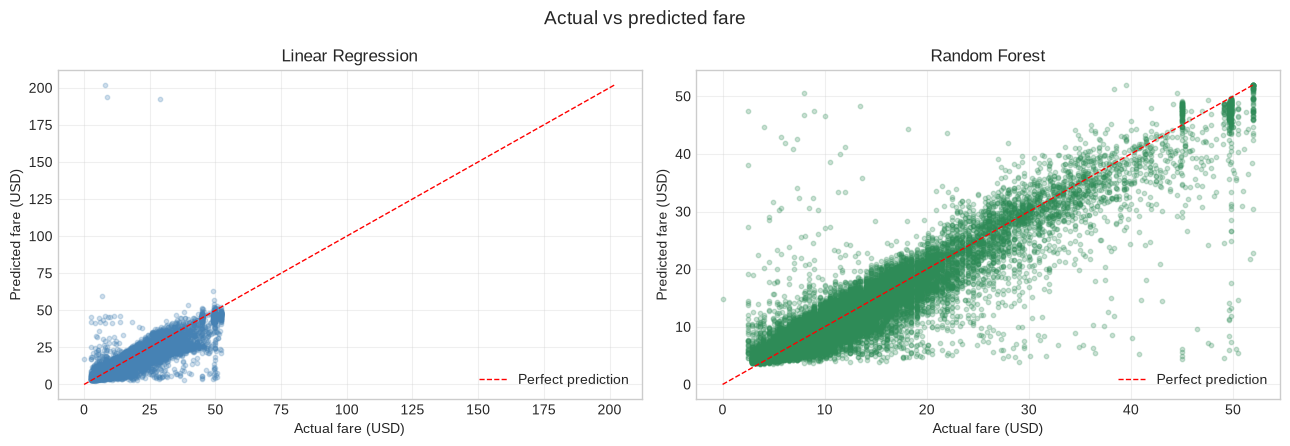

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for axis, predictions, title, colour in [
    (axes[0], linear_predictions, "Linear Regression", "steelblue"),
    (axes[1], forest_predictions, "Random Forest", "seagreen"),
]:
    axis.scatter(y_test, predictions, alpha=0.25, s=10, color=colour)
    limit = max(y_test.max(), predictions.max())
    axis.plot([0, limit], [0, limit], "r--", linewidth=1, label="Perfect prediction")
    axis.set_xlabel("Actual fare (USD)")
    axis.set_ylabel("Predicted fare (USD)")
    axis.set_title(title)
    axis.legend()
    axis.grid(alpha=0.3)

plt.suptitle("Actual vs predicted fare", fontsize=14)
plt.tight_layout()
plt.show()

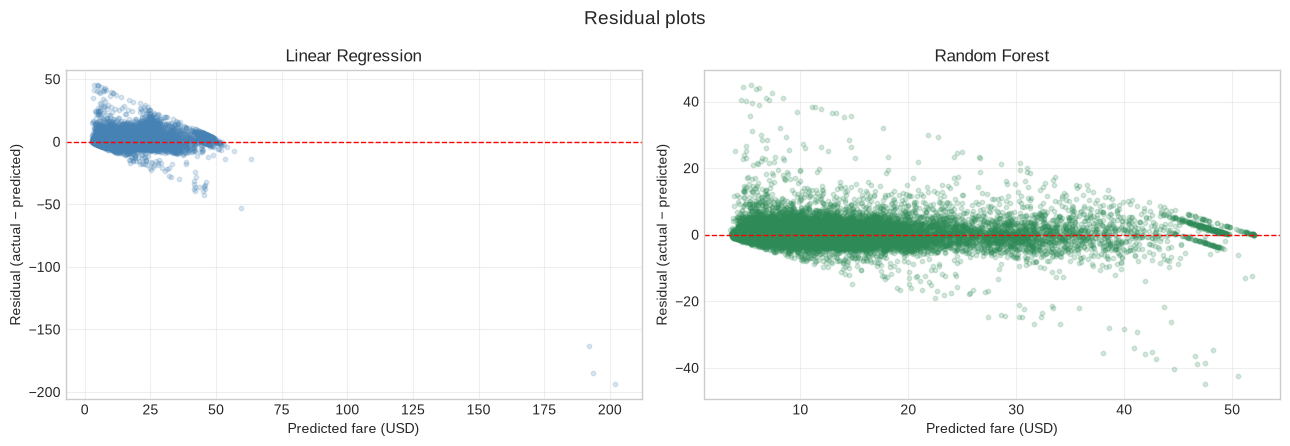

In [21]:
# Residual plots: a good model should have residuals centred around zero.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for axis, predictions, title, colour in [
    (axes[0], linear_predictions, "Linear Regression", "steelblue"),
    (axes[1], forest_predictions, "Random Forest", "seagreen"),
]:
    residuals = y_test - predictions
    axis.scatter(predictions, residuals, alpha=0.2, s=10, color=colour)
    axis.axhline(0, color="red", linestyle="--", linewidth=1)
    axis.set_xlabel("Predicted fare (USD)")
    axis.set_ylabel("Residual (actual − predicted)")
    axis.set_title(title)
    axis.grid(alpha=0.3)
plt.suptitle("Residual plots", fontsize=14)
plt.tight_layout()
plt.show()

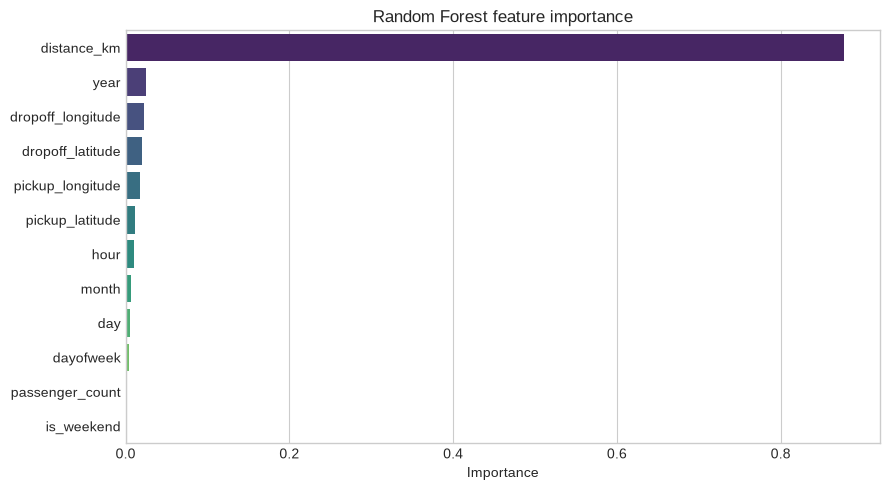

,feature,importance
11,distance_km,0.877362
8,year,0.024761
2,dropoff_longitude,0.021949
3,dropoff_latitude,0.019772
0,pickup_longitude,0.017873
1,pickup_latitude,0.010993
5,hour,0.010332
7,month,0.006039
6,day,0.005081
9,dayofweek,0.003650


In [22]:
# Feature importance from the Random Forest.
importance = pd.DataFrame(
    {
        "feature": feature_columns,
        "importance": random_forest.feature_importances_,
    }
).sort_values("importance", ascending=False)

plt.figure(figsize=(9, 5))
sns.barplot(data=importance, x="importance", y="feature", palette="viridis")
plt.title("Random Forest feature importance")
plt.xlabel("Importance")
plt.ylabel("")
plt.tight_layout()
plt.show()

importance

In [23]:
# A few individual predictions for a test-case table.
sample_indices = [0, 1, 2, 3, 4]
sample_results = pd.DataFrame(
    {
        "actual fare": y_test.iloc[sample_indices].values,
        "linear prediction": linear_predictions[sample_indices],
        "random forest prediction": forest_predictions[sample_indices],
        "distance (km)": X_test.iloc[sample_indices]["distance_km"].values,
    }
)
sample_results["linear error"] = (
    sample_results["linear prediction"] - sample_results["actual fare"]
)
sample_results["forest error"] = (
    sample_results["random forest prediction"] - sample_results["actual fare"]
)
sample_results

,actual fare,linear prediction,random forest prediction,distance (km),linear error,forest error
0,6.9,7.726823,6.597358,1.932628,0.826823,-0.302642
1,20.5,9.292029,9.954016,1.683624,-11.207971,-10.545984
2,5.7,5.926716,5.912670,1.546908,0.226716,0.212670
3,3.7,3.877621,4.135349,0.579452,0.177621,0.435349
4,16.1,17.157500,15.566085,6.022481,1.057500,-0.533915


In [24]:
# ============================================================================
# DETAILED OUTPUT EXPLANATION
# ============================================================================
print("DETAILED OUTPUT EXPLANATION - ML Practical 1 (Uber fare prediction)")
print("=" * 78)
print(
    "The task is regression: predict a continuous fare in USD. The report\n"
    "below reads the cleaned dataset, the correlation analysis, the two model\n"
    "scores and the feature importance, then explains what each number means."
)

print("\n1. CLEANED DATASET")
print("-" * 78)
print(f"Rows remaining after cleaning : {len(df):,}")
print(f"Columns in the cleaned frame  : {df.shape[1]}")
print(f"Training rows                 : {len(X_train):,}")
print(f"Test rows                     : {len(X_test):,}")
print(f"Features used by the models   : {len(feature_columns)}")
print(f"Fare cap (99th percentile)    : ${fare_cap:.2f}")
print(f"Distance cap                  : {distance_cap:.1f} km")
print("Cleaning removed invalid fares, impossible coordinates and extreme")
print("outliers. Without this step, negative fares, zero-distance trips and")
print("GPS errors would dominate the loss and distort the correlations.")

print("\n2. CORRELATION WITH FARE")
print("-" * 78)
fare_correlations = correlation["fare_amount"].drop("fare_amount").sort_values(ascending=False)
for feature, value in fare_correlations.items():
    print(f"  {feature:20s}: {value: .4f}")
print(
    f"Strongest positive linear relationship: {fare_correlations.index[0]} "
    f"(r = {fare_correlations.iloc[0]:.4f})."
)
print("Distance has the largest positive correlation: longer trips tend to cost")
print("more. Correlation measures linear association only; it does not prove")
print("causation and it does not capture non-linear fare rules.")

print("\n3. MODEL PERFORMANCE")
print("-" * 78)
for _, row in comparison.iterrows():
    print(
        f"  {row['model']:20s}: R2={row['R²']:.4f}, "
        f"MAE=${row['MAE (USD)']:.4f}, RMSE=${row['RMSE (USD)']:.4f}"
    )
better_model = "Random Forest" if forest_r2 > linear_r2 else "Linear Regression"
print(f"Better model on this test split: {better_model}")
print(
    f"Random Forest minus Linear Regression: "
    f"delta R2 = {forest_r2 - linear_r2:+.4f}, "
    f"delta MAE = {forest_mae - linear_mae:+.4f} USD, "
    f"delta RMSE = {forest_rmse - linear_rmse:+.4f} USD"
)
print(
    f"Random Forest reduces MAE by "
    f"{100 * (linear_mae - forest_mae) / linear_mae:.2f}% relative to the "
    "linear baseline."
)
print("R2 is the fraction of fare variance explained; 1.0 is perfect and 0.0")
print("means the model is no better than predicting the mean. MAE is the")
print("average absolute dollar error. RMSE is in dollars too, but it squares")
print("errors first, so a few large mistakes raise it more than MAE.")

print("\n4. FEATURE IMPORTANCE AND RESIDUALS")
print("-" * 78)
for _, row in importance.head(8).iterrows():
    print(f"  {row['feature']:20s}: {row['importance']:.4f}")
print(f"Top feature: {importance.iloc[0]['feature']}")
print("Random Forest importance is the average reduction in impurity produced")
print("by splits on that feature. It describes how the model uses the feature,")
print("not a causal effect. Distance dominates because it is the main driver of")
print("fare; coordinates and time features add smaller corrections.")
print("The residual plots show that errors are not constant: expensive trips")
print("have larger absolute errors (heteroscedasticity). A log transform of the")
print("target or a quantile model could reduce this effect.")

print("\n5. SAMPLE PREDICTIONS")
print("-" * 78)
for _, row in sample_results.iterrows():
    print(
        f"  actual=${row['actual fare']:.2f}, "
        f"linear=${row['linear prediction']:.2f}, "
        f"forest=${row['random forest prediction']:.2f}, "
        f"distance={row['distance (km)']:.2f} km"
    )
print("The sample rows show why a single prediction can be far from the actual")
print("fare: the same distance can have different base fares, surcharges and")
print("traffic conditions that are not present in the dataset.")

print("\n6. TAKEAWAY")
print("-" * 78)
print("Linear Regression is a transparent baseline; Random Forest captures")
print("non-linearities and interactions and performs better on this split.")
print("The result is not a production fare model: weather, traffic and road")
print("distance are missing, and a single train/test split has sampling noise.")
print("Next steps: cross-validation, log-transforming fare and geo-features.")

DETAILED OUTPUT EXPLANATION - ML Practical 1 (Uber fare prediction)
The task is regression: predict a continuous fare in USD. The report
below reads the cleaned dataset, the correlation analysis, the two model
scores and the feature importance, then explains what each number means.

1. CLEANED DATASET
------------------------------------------------------------------------------
Rows remaining after cleaning : 190,844
Columns in the cleaned frame  : 14
Training rows                 : 152,675
Test rows                     : 38,169
Features used by the models   : 12
Fare cap (99th percentile)    : $52.00
Distance cap                  : 100.0 km
Cleaning removed invalid fares, impossible coordinates and extreme
outliers. Without this step, negative fares, zero-distance trips and
GPS errors would dominate the loss and distort the correlations.

2. CORRELATION WITH FARE
------------------------------------------------------------------------------
  distance_km         :  0.8610
  year     

### Observations

1. **Distance is the dominant feature.** It has the strongest positive
   correlation with fare and the highest Random Forest importance. This is
   expected: longer trips cost more.
2. **Random Forest outperforms Linear Regression** on all three metrics. The
   relationship between fare and the features is non-linear (base fare,
   distance tiers, time-of-day surcharges, airport trips), which a single
   linear equation cannot capture.
3. **Outliers matter.** Fares below zero, coordinates outside the valid range
   and trips with zero distance are data errors. Keeping them would distort
   both the correlation analysis and the model.
4. **Residuals are heteroscedastic.** The spread of errors increases with the
   predicted fare; expensive trips are harder to predict. A log transform of
   the target or a quantile model could help.
5. **Time features have modest importance.** Hour and weekday capture
   surcharges and traffic patterns, but they are weaker than distance.

### Limitations and improvements

- Coordinates are raw; geo-clustering (e.g. distance to airports, city centre)
  would add useful information.
- Weather, traffic and road distance are not in the dataset.
- A log transformation of `fare_amount` can reduce the influence of expensive
  trips.
- Gradient boosting (XGBoost/LightGBM) often improves on a Random Forest.
- Cross-validation would give a more stable estimate than a single split.

## 5. Conclusion

We pre-processed the Uber fares dataset, handled invalid records and outliers,
engineered time and distance features, and analysed correlations. Linear
Regression provided a simple baseline, while Random Forest Regression captured
non-linear effects and achieved a higher $R^2$ with lower MAE and RMSE. The
experiment shows the importance of feature engineering (especially Haversine
distance) and of choosing a model that matches the structure of the data.

## 6. Viva questions

| Question | Short answer |
|---|---|
| Why is Haversine distance used instead of Euclidean distance? | Latitude/longitude are spherical coordinates; Haversine gives the great-circle distance. |
| What does $R^2$ measure? | The proportion of variance in the target explained by the model. |
| What is the difference between MAE and RMSE? | RMSE squares the errors, so it penalises large errors more. |
| Why does Random Forest outperform Linear Regression here? | It captures non-linearities and feature interactions. |
| How are outliers detected with the IQR rule? | Values outside $[Q_1-1.5\text{IQR}, Q_3+1.5\text{IQR}]$. |
| Why not remove every IQR outlier? | Some are genuine long/expensive trips; removing them can bias the model. |
| What is feature importance in a Random Forest? | The average reduction in impurity contributed by a feature across the trees. |
| What is one limitation of this model? | It does not use traffic, weather or road-network distance. |